# Post Test 4 - Klasifikasi Gambar Rock Paper Scissors (CNN)
Nama : ...
NIM  : ...

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Menyiapkan Dataset
Dataset Rock Paper Scissors saya upload ke google drive, terus didownload pakai gdown dan diekstrak ke /content/ biar bacanya lebih cepat. Isi foldernya ada train, test, sama validation.

In [2]:
!gdown 1XyBMeARzmz7oVjHNPzCOkSb0k672PSZQ
!unzip -q RockPaperScissors.zip -d /content/
!ls /content/Rock-Paper-Scissors

Downloading...
From (original): https://drive.google.com/uc?id=1XyBMeARzmz7oVjHNPzCOkSb0k672PSZQ
From (redirected): https://drive.google.com/uc?id=1XyBMeARzmz7oVjHNPzCOkSb0k672PSZQ&confirm=t&uuid=802202a9-cd72-413e-b455-0b9b57e5f517
To: /content/RockPaperScissors.zip
100% 474M/474M [00:08<00:00, 57.8MB/s]
test  train  validation


## Import Library
Library yang dipakai: tensorflow buat bikin model, matplotlib & seaborn buat visualisasi, sklearn buat confusion matrix dan classification report. Sekalian ngecek GPU udah kebaca atau belum (pakai GPU T4 dari colab).

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load Dataset
Data train dibagi 80% buat training dan 20% buat validasi pakai validation_split. Folder validation yang dari datasetnya ga dipake karena isinya cuma 33 gambar dan ga ada subfolder kelasnya, jadi ga bisa dibaca labelnya.

Untuk data test shuffle nya dimatiin supaya urutannya ga berubah, soalnya nanti dibandingin sama hasil prediksi di confusion matrix. Ukuran gambar semua diubah ke 224x224 karena itu ukuran input MobileNetV2.

Dataset ini cuma punya 3 kelas (paper, rock, scissors) jadi contoh gambar yang ditampilin dari 3 kelas itu aja.

In [4]:
base_dir = '/content/Rock-Paper-Scissors'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'train'),
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'train'),
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_name = train_ds.class_names
print(class_name)

Found 2520 files belonging to 3 classes.
Using 2016 files for training.
Found 2520 files belonging to 3 classes.
Using 504 files for validation.
['paper', 'rock', 'scissors']


In [5]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(base_dir, 'test'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 372 files belonging to 3 classes.


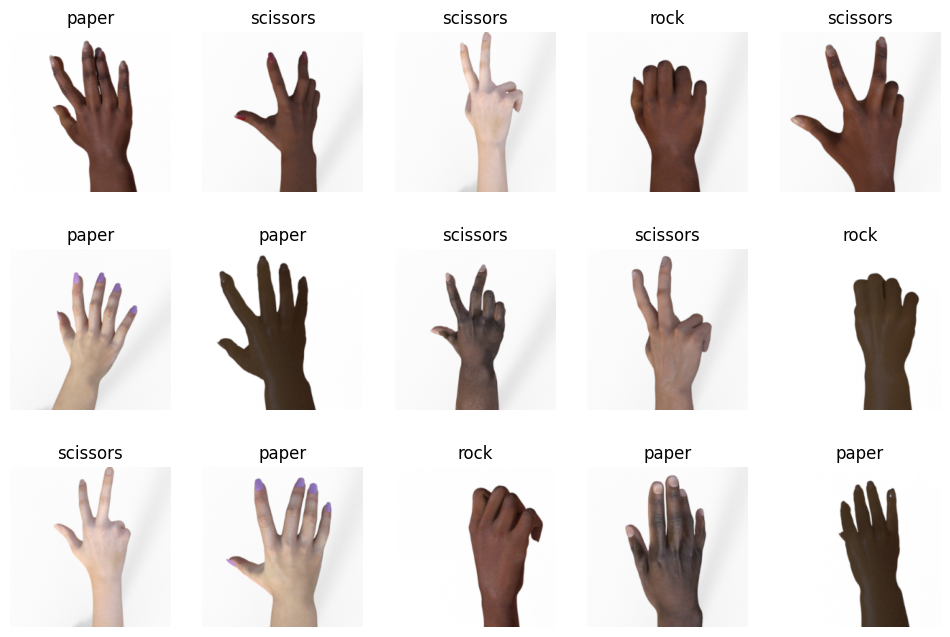

In [8]:
plt.figure(figsize=(12,8))
for images, labels in train_ds.take(1):
  for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_name[labels[i]])
    plt.axis('off')
plt.show()

## Jumlah Gambar per Kelas
Ngitung jumlah gambar tiap kelas di folder train pakai os.listdir terus dibikin bar chart. Hasilnya masing-masing kelas ada 840 gambar, jadi datanya udah seimbang dan ga perlu balancing.

{'paper': 840, 'rock': 840, 'scissors': 840}


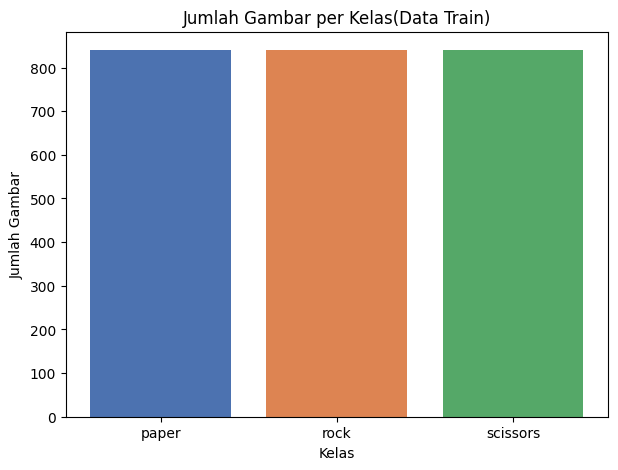

In [11]:
jumlah = {}
for kelas in class_name:
  jumlah[kelas] = len(os.listdir(os.path.join(base_dir, 'train' ,kelas)))
print(jumlah)

plt.figure(figsize = (7, 5))
plt.bar(jumlah.keys(), jumlah.values(), color=['#4c72b0', '#dd8452', '#55a868'])
plt.title('Jumlah Gambar per Kelas(Data Train)')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')
plt.show()

## Data Augmentation
Augmentasi yang dipakai ada 3: flip horizontal, rotasi, dan zoom (random). Tujuannya biar gambar trainingnya lebih variatif jadi model ga gampang overfitting. Layer augmentasi ini nanti dimasukin ke dalam model, jadi otomatis cuma jalan pas training aja.

Contoh hasil augmentasinya di bawah, tiap di run hasilnya beda-beda karena random.

In [12]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

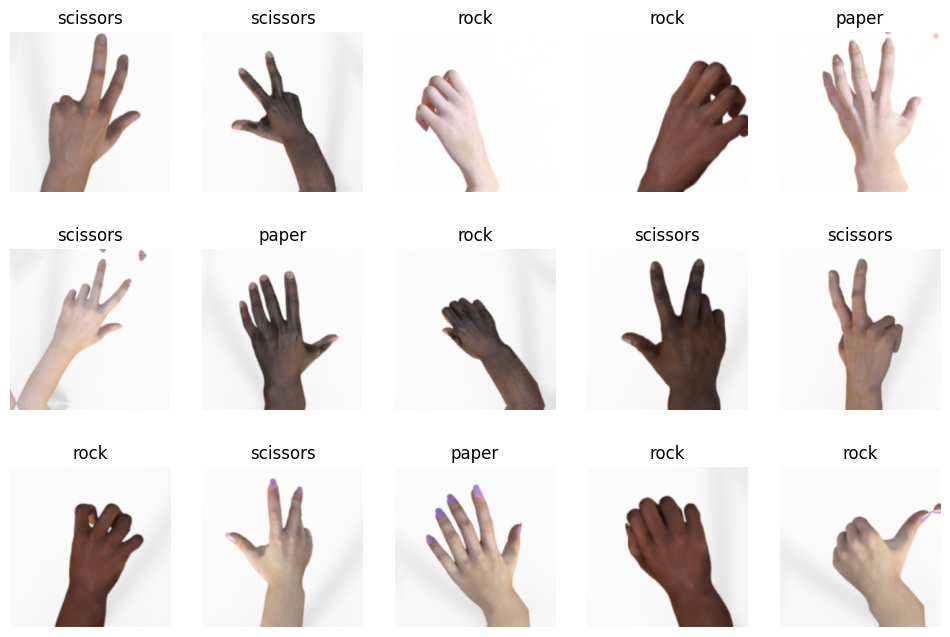

In [15]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    aug_images = data_augmentation(images, training=True)
    for i in range(15):
        plt.subplot(3, 5, i + 1)
        plt.imshow(aug_images[i].numpy().astype('uint8'))
        plt.title(class_name[labels[i]])
        plt.axis('off')
plt.show()

## Membuat Model
Model yang dipakai transfer learning MobileNetV2 dengan bobot imagenet. include_top=False biar layer output bawaannya (1000 kelas) ga ikut, terus base_model nya di freeze (trainable = False) supaya bobotnya ga berubah waktu training.

Urutan layernya: augmentasi -> rescaling (piksel diubah ke range -1 sampai 1 sesuai yang diminta MobileNetV2) -> MobileNetV2 -> GlobalAveragePooling -> Dropout 0.2 -> Dense 3 kelas softmax. Loss nya pakai sparse_categorical_crossentropy karena labelnya masih angka (0,1,2), bukan one-hot.

Di summary keliatan trainable params cuma 3.843, sisanya 2,2 juta parameter punya MobileNetV2 yang di freeze.

In [16]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [17]:
model = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_name), activation='softmax')

])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Callbacks & Training
Callback yang dipakai EarlyStopping, monitor val_loss dengan patience 3. Jadi kalau val_loss ga turun 3 epoch berturut-turut training bakal berhenti sendiri, dan restore_best_weights biar bobot yang dipake bobot yang paling bagus. Epoch maksimal di set 20.

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [19]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - accuracy: 0.7981 - loss: 0.5228 - val_accuracy: 0.9921 - val_loss: 0.1688
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9702 - loss: 0.1440 - val_accuracy: 0.9940 - val_loss: 0.0914
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9846 - loss: 0.0831 - val_accuracy: 0.9980 - val_loss: 0.0592
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9901 - loss: 0.0659 - val_accuracy: 0.9980 - val_loss: 0.0413
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9921 - loss: 0.0488 - val_accuracy: 1.0000 - val_loss: 0.0312
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9945 - loss: 0.0411 - val_accuracy: 0.9980 - val_loss: 0.0274
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9931 - loss: 0.0396 - val_accuracy: 0.9980 - val_loss: 0.0236
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9965 - loss: 0.0287 - val_accuracy: 0.9980 - 

## Grafik Akurasi dan Loss
Ternyata trainingnya jalan sampai 20 epoch penuh, EarlyStopping nya ga sempet aktif karena val_loss masih terus turun sedikit-sedikit sampai akhir (dari 0.1688 di epoch 1 jadi sekitar 0.005-0.006).

Akurasi train naik dari 0.79 di epoch pertama jadi 0.99, sedangkan val_accuracy udah 0.99 dari epoch 1 dan dapet 1.0 mulai epoch 9. Val accuracy lebih tinggi dari train accuracy di awal, kemungkinan karena augmentasi sama dropout cuma aktif pas training jadi data train lebih "susah" buat model.

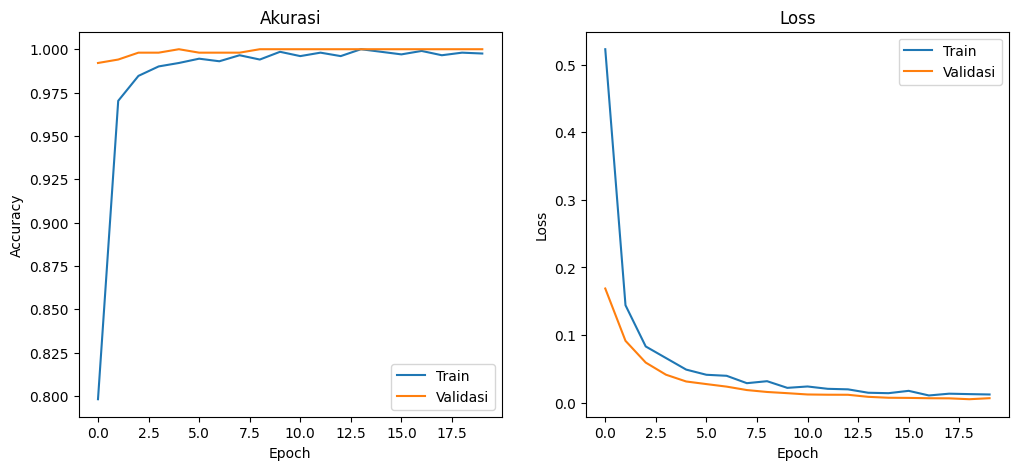

In [20]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Train')
plt.plot(val_acc, label='Validasi')
plt.title('Akurasi')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train')
plt.plot(val_loss, label='Validasi')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## Evaluasi Model
Model dites pakai data test (372 gambar) yang belum pernah dipakai waktu training. Evaluasinya pakai classification report dan confusion matrix.

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step
=== Classification Report ===
              precision    recall  f1-score   support

       paper       1.00      0.67      0.80       124
        rock       0.77      1.00      0.87       124
    scissors       0.97      1.00      0.98       124

    accuracy                           0.89       372
   macro avg       0.91      0.89      0.89       372
weighted avg       0.91      0.89      0.89       372



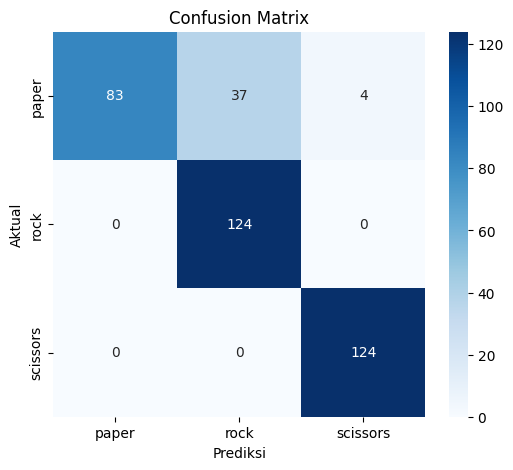

In [21]:
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.concatenate([y for x, y in test_ds], axis=0)

print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_name))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_name, yticklabels=class_name)
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()


### Analisis Hasil
Akurasi di data test 0.89, lebih rendah dibanding validasi yang sampai 1.0. Dari confusion matrix:
- rock dan scissors ketebak semua (124/124)
- paper yang paling banyak salah, cuma 83 yang bener, 37 ketebak rock dan 4 ketebak scissors. Makanya recall paper cuma 0.67 dan precision rock turun jadi 0.77

Menurut saya bedanya hasil validasi sama test ini karena data validasi diambil dari folder train juga, jadi gambarnya masih mirip-mirip (tangan & backgroundnya sama). Sedangkan data test kemungkinan gambarnya agak beda jadi model belum terlalu bisa generalisasi, terutama buat paper. Mungkin bisa diperbaiki dengan augmentasi yang lebih banyak (misal brightness/contrast) atau fine tuning beberapa layer terakhir MobileNetV2.